# 03 - Filtragem Colaborativa com SVD / Funk SVD

## Objetivo

Implementar e treinar um modelo de fatoração de matriz (**Funk SVD**) para recomendação personalizada de eventos, com fundamentação matemática completa e pipeline end-to-end:

1. **Carregamento e exploração** dos dados de interação usuário-espetáculo
2. **Busca de hiperparâmetros** via `GridSearchCV` com validação cruzada (3-fold)
3. **Treinamento do modelo final** com os melhores parâmetros encontrados
4. **Avaliação** em conjunto de teste holdout (RMSE, MAE)
5. **Geração de recomendações** top-10 para um usuário exemplo
6. **Análise dos fatores latentes** aprendidos pelo modelo

## Contexto do Projeto

Este notebook faz parte de um sistema de recomendação de eventos desenvolvido para a plataforma **Portal Aventura**, que produz shows, espetáculos musicais e teatrais.

### Dataset
O dataset processado contém **109.916 interações** entre aproximadamente **68 mil usuários** e **571 espetáculos**. Cada linha representa a interação de um usuário com um evento e possui as colunas:

| Coluna | Tipo | Descrição |
|---|---|---|
| `user_id` | int | Identificador único do usuário |
| `item_id` | str | Nome do espetáculo/evento |
| `ranking` | int (1–5) | Dias distintos de interação com o evento (feedback implícito) |
| `valor_medio_ingresso` | float | Preço médio do ingresso (R$) |
| `tipo_evento` | str | Categoria: Show Musical, Stand-Up, Espetáculo Teatral, etc. |

### Feedback implícito
O campo `ranking` **não é uma avaliação explícita** do usuário — representa quantos dias distintos o usuário interagiu com o evento (de 1 a 5). Valores mais altos indicam maior engajamento, mas podem ser influenciados por outros fatores (disponibilidade de agenda, campanhas de marketing), o que introduz ruído.

### Posição no pipeline
```
01_analise_exploratoria_dados  →  02_knn  →  [03_svd]  →  04_avaliacao_inferencia
```
O modelo treinado aqui (`svd_model.joblib`) será comparado ao KNN colaborativo no notebook de avaliação final.

## 1. Setup

Nesta seção carregamos as bibliotecas, configuramos parâmetros globais e definimos os caminhos de arquivo de forma portável.

### Bibliotecas utilizadas

| Biblioteca | Papel neste notebook |
|---|---|
| `pandas` | Carregar e manipular o dataset em formato tabular (DataFrame) |
| `numpy` | Operações numéricas e configuração da semente aleatória para reprodutibilidade |
| `matplotlib` / `seaborn` | Visualização dos resultados de avaliação (histograma de erros, scatter) |
| `joblib` | Serializar (salvar/carregar) o modelo treinado em disco |
| `scikit-surprise` | Framework de filtragem colaborativa: SVD, Reader, GridSearchCV, métricas |
| `pathlib` | Resolver caminhos de arquivo de forma portável (Windows/Linux/Mac) |

> **Por que `pathlib` em vez de caminhos relativos?**  
> Em ambientes como o VS Code Jupyter, o diretório de trabalho do kernel nem sempre coincide com a pasta do notebook. O bloco `try/except` abaixo usa a variável `__vsc_ipynb_file__` (injetada pelo VS Code) para localizar o notebook e calcular os caminhos a partir dele — garantindo que o dataset seja encontrado independentemente de onde o kernel foi iniciado.

In [1]:
import os
import pathlib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split as skl_split
from surprise import SVD, Dataset, Reader, accuracy
from surprise.model_selection import GridSearchCV

warnings.filterwarnings("ignore")
np.random.seed(42)
sns.set_theme(style="whitegrid")

# Resolve o diretório do notebook independente do cwd do kernel
try:
    _HERE = pathlib.Path(__vsc_ipynb_file__).resolve().parent
except NameError:
    _HERE = pathlib.Path(os.path.abspath("")).resolve()

DATA_PATH  = _HERE.parent / "dataset" / "dataset.csv"
MODELS_DIR = _HERE.parent / "models"

print("Bibliotecas carregadas com sucesso.")
print(f"Dataset : {DATA_PATH}")
print(f"Modelos : {MODELS_DIR}")

Bibliotecas carregadas com sucesso.
Dataset : C:\Users\cadus\CADU_FILES\Inteli\Projeto 6 - Aventura\g02\src\dataset\dataset.csv
Modelos : C:\Users\cadus\CADU_FILES\Inteli\Projeto 6 - Aventura\g02\src\models


## 2. Fundamentação Teórica

### 2.1. Motivação: o problema de recomendação como matriz esparsa

Imagine uma planilha onde cada linha é um usuário e cada coluna é um espetáculo. Cada célula contém o nível de engajamento daquele usuário com aquele espetáculo. A grande maioria das células está **vazia** — a maior parte dos usuários não interagiu com a maior parte dos espetáculos:

|            | Show A | Musical B | Stand-Up C | Teatro D | Show E |
|------------|:------:|:---------:|:----------:|:--------:|:------:|
| Usuário 1  |   3    |     ?     |     5      |    ?     |   1    |
| Usuário 2  |   ?    |     4     |     ?      |    2     |   ?    |
| Usuário 3  |   1    |     ?     |     ?      |    ?     |   4    |
| Usuário 4  |   ?    |     ?     |     3      |    5     |   ?    |

Os `?` são os pares que nunca foram observados — **exatamente o que queremos prever**. No nosso dataset: ~68 mil usuários × 571 espetáculos = ~38 milhões de combinações possíveis, mas apenas 109.916 observadas (~99,7% são `?`).

---

### 2.2. SVD clássico — e por que não funciona aqui

A Decomposição em Valores Singulares (**SVD**) decompõe uma matriz $R \in \mathbb{R}^{m \times n}$ em três fatores:

$$R = U \Sigma V^T$$

- $U \in \mathbb{R}^{m \times m}$: vetores singulares à esquerda (representam usuários)
- $\Sigma \in \mathbb{R}^{m \times n}$: valores singulares (importância de cada "tema")
- $V \in \mathbb{R}^{n \times n}$: vetores singulares à direita (representam itens)

**Problema:** o SVD clássico exige que **todos os valores da matriz sejam conhecidos**. Com 99,7% de entradas ausentes, é matematicamente inviável aplicá-lo diretamente. Não temos como decompor o que não existe.

---

### 2.3. Funk SVD — intuição antes da fórmula

Em vez de decompor $R$ diretamente, o **Funk SVD** (proposto por Simon Funk durante o Netflix Prize em 2006) *aprende* representações compactas de usuários e itens **a partir apenas das interações observadas**.

**Intuição:** cada usuário e cada espetáculo são representados por um vetor de $k$ números reais — os **fatores latentes**. Esses fatores capturam preferências e características abstratas que o modelo infere dos padrões de interação:

- Um fator pode capturar "preferência por shows de comédia stand-up"
- Outro pode capturar "afinidade com eventos de alto valor médio de ingresso"
- Outro ainda pode representar "engajamento com espetáculos teatrais clássicos"

O modelo decide **automaticamente** o que cada fator significa — não recebemos rótulos, apenas os padrões de interação.

---

### 2.4. A fórmula de predição — cada termo explicado

A predição do ranking do usuário $u$ para o item $i$ é:

$$\hat{r}_{ui} = \underbrace{\mu}_{\substack{\text{média global} \\ \text{de todos os ratings}}} + \underbrace{b_u}_{\substack{\text{viés do usuário} \\ \text{(usuário sempre alto/baixo)}}} + \underbrace{b_i}_{\substack{\text{viés do item} \\ \text{(espetáculo popular/impopular)}}} + \underbrace{p_u \cdot q_i^T}_{\substack{\text{preferência personalizada} \\ \text{(produto interno latente)}}}$$

| Componente | O que representa | Exemplo intuitivo |
|---|---|---|
| $\mu$ | Média global de todos os ratings | "A maioria das pessoas dá ranking 1" |
| $b_u$ | Tendência individual do usuário | "Este usuário tende a interagir mais do que a média" |
| $b_i$ | Popularidade intrínseca do item | "Este show é amplamente visitado independente do perfil" |
| $p_u \cdot q_i^T$ | Alinhamento personalizado usuário-item | "Este usuário gosta de stand-up E este show é de stand-up" |

---

### 2.5. Função de perda — o que o modelo minimiza

O modelo minimiza o erro quadrático sobre todas as interações observadas, com **regularização L2** para evitar overfitting:

$$\min_{P, Q, b} \sum_{(u,i) \in \mathcal{K}} \underbrace{(r_{ui} - \hat{r}_{ui})^2}_{\text{erro de predição}} + \lambda \underbrace{\left(||p_u||^2 + ||q_i||^2 + b_u^2 + b_i^2\right)}_{\text{penaliza parâmetros grandes}}$$

A regularização $\lambda$ é essencial com 99,7% de esparsidade: sem ela, o modelo poderia memorizar as poucas interações observadas em vez de aprender padrões generalizáveis.

---

### 2.6. Otimização via SGD — como o modelo aprende passo a passo

Para cada interação $(u, i, r_{ui})$ no treino, calculamos o erro $e_{ui} = r_{ui} - \hat{r}_{ui}$ e atualizamos todos os parâmetros em pequenos passos:

$$p_u \leftarrow p_u + \eta \left( e_{ui} \cdot q_i - \lambda \cdot p_u \right)$$
$$q_i \leftarrow q_i + \eta \left( e_{ui} \cdot p_u - \lambda \cdot q_i \right)$$
$$b_u \leftarrow b_u + \eta \left( e_{ui} - \lambda \cdot b_u \right)$$
$$b_i \leftarrow b_i + \eta \left( e_{ui} - \lambda \cdot b_i \right)$$

Uma passagem completa por todas as interações é chamada de **época** (`n_epochs`). O modelo vai iterativamente reduzindo o erro de predição até convergir.

### 2.7. Hiperparâmetros do Funk SVD

Os hiperparâmetros controlam a estrutura e o comportamento do modelo. Nenhum valor é universalmente ótimo — depende das características do dataset (tamanho, esparsidade, escala de ratings). Por isso, usamos busca em grade com validação cruzada para encontrar a combinação ideal.

| Hiperparâmetro | Notação | Descrição | Se muito baixo | Se muito alto |
|---|---|---|---|---|
| `n_factors` | $k$ | Dimensão do espaço latente (número de temas implícitos aprendidos) | Underfitting: não captura preferências complexas | Overfitting: memoriza o treino, generaliza mal em dados esparsos |
| `lr_all` | $\eta$ | Taxa de aprendizado do SGD | Convergência muito lenta; pode parar em mínimo ruim | Convergência instável: o modelo "oscila" e não converge |
| `reg_all` | $\lambda$ | Regularização L2 aplicada a todos os parâmetros | Vetores latentes crescem sem controle → overfitting | Vetores latentes encolhem demais → underfitting |
| `n_epochs` | — | Número de épocas (passagens completas sobre os dados de treino) | Modelo ainda está aprendendo, convergência incompleta | Custo computacional alto com retornos decrescentes |

**Espaço de busca:**
- `n_factors` ∈ {20, 50, 100}
- `lr_all` ∈ {0.002, 0.005, 0.010}
- `reg_all` ∈ {0.02, 0.05, 0.10}
- `n_epochs` = 20 durante a busca (reduzido para viabilidade computacional); **50 no modelo final**

Total: 3 × 3 × 3 = **27 combinações** × 3 folds de CV = **81 modelos treinados**.

## 3. Treinamento

### 3.0. Carregamento dos Dados

O dataset é carregado de `src/dataset/dataset.csv`. Para este notebook de **filtragem colaborativa pura**, usamos apenas as três colunas que descrevem interações diretamente:

- `user_id`: quem interagiu
- `item_id`: com qual espetáculo
- `ranking`: intensidade da interação (1–5 dias distintos)

As colunas `valor_medio_ingresso` e `tipo_evento` são **ignoradas aqui** de forma intencional: a filtragem colaborativa aprende exclusivamente do padrão coletivo de interações — sem precisar conhecer o conteúdo dos eventos. Essas colunas seriam aproveitadas em abordagens híbridas (filtragem colaborativa + baseada em conteúdo).

#### O que esperar da exploração dos dados

| Aspecto | O que observar | Por que importa |
|---|---|---|
| **Esparsidade ~99,7%** | Quase toda a matriz usuário-item está vazia | É exatamente o cenário para o qual o Funk SVD foi projetado |
| **Distribuição do ranking** | Maioria com ranking=1 | Confirma que o feedback é implícito e discreto, não uma avaliação subjetiva |
| **Usuários vs espetáculos** | ~68k usuários, ~571 espetáculos | Muitos mais usuários do que itens — a matriz tem mais linhas do que colunas |
| **Diversidade de eventos** | Tipos: Show Musical, Stand-Up, Teatro, etc. | Heterogeneidade dos itens desafia o modelo a aprender preferências por gênero |

In [2]:
df = pd.read_csv(DATA_PATH)

print(f"Dimensão: {df.shape[0]:,} linhas × {df.shape[1]} colunas")
print(f"\nTipos de dados:\n{df.dtypes}")
print(f"\nDistribuição do ranking (feedback implícito):")
print(df["ranking"].value_counts().sort_index())
print(f"\nEscala: {df['ranking'].min()} a {df['ranking'].max()}")
print(f"\nUsuários únicos  : {df['user_id'].nunique():,}")
print(f"Espetáculos únicos: {df['item_id'].nunique():,}")

n_users = df["user_id"].nunique()
n_items = df["item_id"].nunique()
sparsity = (1 - len(df) / (n_users * n_items)) * 100
print(f"Esparsidade da matriz: {sparsity:.2f}%")

df.head()

Dimensão: 109,916 linhas × 5 colunas

Tipos de dados:
user_id                   int64
item_id                     str
ranking                   int64
valor_medio_ingresso    float64
tipo_evento                 str
dtype: object

Distribuição do ranking (feedback implícito):
ranking
1    103553
2      5621
3       582
4        97
5        63
Name: count, dtype: int64

Escala: 1 a 5

Usuários únicos  : 68,499
Espetáculos únicos: 449
Esparsidade da matriz: 99.64%


,user_id,item_id,ranking,valor_medio_ingresso,tipo_evento
0,1,UM MALLANDRO NA QUARENTENA COM SERGIO MALLANDRO,1,120.0,Show Stand-Up
1,2,DOMINGUINHOS - ISSO AQUI TÁ BOM DEMAIS,1,50.0,Show Musical
2,3,A NOVIÇA REBELDE,1,225.0,Espetáculo Musical
3,4,MUSICAL HAIRSPRAY,1,350.0,Espetáculo Musical
4,5,A NOVIÇA REBELDE,1,125.0,Espetáculo Musical


#### Interpretando os números da exploração

Os valores exibidos acima revelam aspectos importantes do problema:

- **Distribuição do ranking**: espere que a maioria das interações tenha `ranking=1`. Isso confirma que o feedback é implícito e discreto — a maior parte dos usuários visitou cada evento apenas uma vez. Rankings 4 e 5 são raros e representam usuários com alto engajamento.

- **Esparsidade ~99,7%**: de todas as combinações possíveis (usuários × espetáculos), menos de 0,3% foram observadas. Isso não é um problema do dataset — é a realidade de sistemas de recomendação de eventos. O Funk SVD lida com isso nativamente.

- **Desequilíbrio de popularidade (cauda longa)**: poucos espetáculos concentram a maioria das interações. Os vieses de item ($b_i$) na fórmula do Funk SVD capturam exatamente esse fenômeno — espetáculos populares recebem um viés positivo que é separado da preferência personalizada do usuário.

In [3]:
reader = Reader(rating_scale=(1, 5))
data = Dataset.load_from_df(df[["user_id", "item_id", "ranking"]], reader)

print("Dataset carregado no formato Surprise.")
print("rating_scale=(1, 5) — escala do feedback implícito por dias de interação")

Dataset carregado no formato Surprise.
rating_scale=(1, 5) — escala do feedback implícito por dias de interação


#### O que o `Reader` e o `Dataset` do Surprise fazem?

O **`Reader`** instrui a biblioteca sobre a escala do campo de rating:
- `rating_scale=(1, 5)` indica que os valores válidos vão de 1 a 5
- O Surprise usa essa informação para clipar predições dentro do intervalo e para normalização interna
- Se a escala estiver errada, o modelo pode fazer predições fora dos limites ou calcular erros de forma inconsistente

O **`Dataset.load_from_df`** converte o DataFrame pandas para o formato interno do Surprise:
- Espera exatamente **3 colunas** na ordem `[user_id, item_id, rating]`
- Mapeia internamente os IDs de usuários e itens para índices inteiros (0, 1, 2, ...)
- O mapeamento inverso é recuperável via `trainset.to_raw_uid(inner_uid)` e `trainset.to_raw_iid(inner_iid)`
- O objeto `data` resultante está pronto para ser passado ao `GridSearchCV` e ao `train_test_split`

In [4]:
df_train, df_test = skl_split(df, test_size=0.20, random_state=42)

data_train = Dataset.load_from_df(df_train[["user_id", "item_id", "ranking"]], reader)
testset    = list(zip(df_test["user_id"], df_test["item_id"], df_test["ranking"]))
trainset   = data_train.build_full_trainset()

print(f"Interações no treino : {trainset.n_ratings:,}")
print(f"Interações no teste  : {len(testset):,}")

Interações no treino : 87,932
Interações no teste  : 21,984


#### Estratégia de avaliação: holdout 80/20

A divisão é feita **no DataFrame** antes de criar os objetos Surprise, garantindo isolamento completo:

- **Treino (80%)**: ~87.900 interações — usadas para ajustar os pesos do modelo **e** para a busca de hiperparâmetros
- **Teste (20%)**: ~22.000 interações — reservadas exclusivamente para avaliação final

**Por que dividir no DataFrame e não via `train_test_split` do Surprise?**

O `GridSearchCV` do Surprise exige um objeto `Dataset` (não um `Trainset`). Se passarmos `data` (dataset completo) ao `gs.fit()`, os registros de teste participam da seleção de hiperparâmetros — vazamento de informação. A solução correta é criar `data_train` apenas com os 80% de treino e passar esse objeto ao `GridSearchCV`:

```
DataFrame completo (100%)
│
├── df_train (80%) → data_train → GridSearchCV (3-fold CV) → melhores hiperparâmetros
│                              → trainset → modelo_avaliacao → avaliação no testset
│
├── df_test  (20%) → testset (lista de tuplas) → avaliação final (RMSE, MAE)
│
└── data (100%)    → full_trainset → modelo_svd (produção, salvo em disco)
```

> **`random_state=42`** garante que a divisão seja reproduzível — sempre os mesmos 20% de interações no conjunto de teste, independente de quando o notebook é executado.

### 3.1. Busca de Hiperparâmetros — GridSearchCV com Validação Cruzada

Não existe uma combinação de hiperparâmetros universalmente ótima. Por isso, testamos sistematicamente 27 combinações e escolhemos a que generaliza melhor para dados não vistos.

#### O que é validação cruzada k-fold?

Em vez de usar uma única divisão treino/validação (o que seria influenciado pela sorte da divisão), a **validação cruzada com k=3 folds** divide o conjunto de dados em 3 partes iguais e repete o processo 3 vezes:

```
Fold 1:  [VALIDAÇÃO] [  TREINO  ] [  TREINO  ]  → RMSE₁
Fold 2:  [  TREINO  ] [VALIDAÇÃO] [  TREINO  ]  → RMSE₂
Fold 3:  [  TREINO  ] [  TREINO  ] [VALIDAÇÃO]  → RMSE₃
                                       ↓
                              RMSE médio = (RMSE₁ + RMSE₂ + RMSE₃) / 3
```

O **RMSE médio** é uma estimativa muito mais confiável da performance real do que uma única divisão.

#### Quantos modelos serão treinados?

```
n_factors : [20, 50, 100]         → 3 opções
lr_all    : [0.002, 0.005, 0.010] → 3 opções
reg_all   : [0.02, 0.05, 0.10]   → 3 opções
─────────────────────────────────────────────
Combinações: 3 × 3 × 3 = 27
× 3 folds  = 81 modelos treinados no total
```

**`n_epochs=20`** durante a busca: reduzimos o número de épocas para tornar os 81 treinos computacionalmente viáveis. O modelo final usará 50 épocas.

**Critério de seleção:** minimização do **RMSE médio** nos folds de validação.

In [5]:
param_grid = {
    "n_factors": [20, 50, 100],
    "lr_all":    [0.002, 0.005, 0.010],
    "reg_all":   [0.02, 0.05, 0.10],
    "n_epochs":  [20],
}

gs = GridSearchCV(
    SVD,
    param_grid,
    measures=["rmse", "mae"],
    cv=3,
    n_jobs=1,
    joblib_verbose=0,
    refit=False,
)
gs.fit(data_train)

print("Melhores hiperparâmetros (RMSE):")
print(gs.best_params["rmse"])
print(f"\nMelhor RMSE (CV): {gs.best_score['rmse']:.4f}")
print(f"Melhor MAE  (CV): {gs.best_score['mae']:.4f}")

Melhores hiperparâmetros (RMSE):
{'n_factors': 20, 'lr_all': 0.002, 'reg_all': 0.1, 'n_epochs': 20}

Melhor RMSE (CV): 0.2869
Melhor MAE  (CV): 0.1180


In [6]:
resultados_gs = pd.DataFrame(gs.cv_results)
colunas_viz = [
    "param_n_factors", "param_lr_all", "param_reg_all",
    "mean_test_rmse", "std_test_rmse", "mean_test_mae",
]
resultados_gs[colunas_viz].sort_values("mean_test_rmse").head(10).round(4)

,param_n_factors,param_lr_all,param_reg_all,mean_test_rmse,std_test_rmse,mean_test_mae
2,20,0.002,0.10,0.2869,0.0019,0.1195
1,20,0.002,0.05,0.2869,0.0018,0.1196
11,50,0.002,0.10,0.2871,0.0018,0.1201
5,20,0.005,0.10,0.2872,0.0019,0.1182
0,20,0.002,0.02,0.2873,0.0018,0.1199
4,20,0.005,0.05,0.2874,0.0018,0.1180
14,50,0.005,0.10,0.2874,0.0018,0.1185
10,50,0.002,0.05,0.2874,0.0020,0.1204
3,20,0.005,0.02,0.2875,0.0018,0.1182
23,100,0.005,0.10,0.2876,0.0018,0.1190


#### Como interpretar a tabela do GridSearchCV

A tabela acima mostra as 27 combinações testadas, ordenadas da melhor (menor RMSE) para a pior:

| Coluna | O que significa | O que procurar |
|---|---|---|
| `mean_test_rmse` | Média do RMSE nos 3 folds | **Menor é melhor** — critério principal de seleção |
| `std_test_rmse` | Desvio padrão do RMSE entre os folds | **Menor é mais estável** — modelos com std alto são sensíveis à divisão dos dados |
| `mean_test_mae` | Média do MAE nos 3 folds | Confirma coerência com o RMSE; deve seguir a mesma tendência |
| `param_n_factors` | Número de fatores latentes testado | Observe se modelos maiores (100) superam os menores (20) |
| `param_lr_all` | Taxa de aprendizado testada | Taxas muito altas geralmente pioram o RMSE |
| `param_reg_all` | Regularização L2 testada | Mais regularização tende a ajudar com alta esparsidade |

**Dica de análise:** prefira combinações com baixo `mean_test_rmse` **e** baixo `std_test_rmse`. Um modelo com RMSE ligeiramente maior mas muito mais estável entre os folds pode ser mais confiável na prática do que o "melhor" instável.

In [7]:
best_params = gs.best_params["rmse"]

modelo_svd = SVD(
    n_factors=best_params["n_factors"],
    lr_all=best_params["lr_all"],
    reg_all=best_params["reg_all"],
    n_epochs=50,
    random_state=42,
    verbose=False,
)

full_trainset = data.build_full_trainset()
modelo_svd.fit(full_trainset)

print("Modelo SVD treinado no dataset completo.")
print(f"  n_factors : {modelo_svd.n_factors}")
print(f"  lr_all    : {best_params['lr_all']}")
print(f"  reg_all   : {best_params['reg_all']}")
print(f"  n_epochs  : {best_params['n_epochs']}")

Modelo SVD treinado no dataset completo.
  n_factors : 20
  lr_all    : 0.002
  reg_all   : 0.1
  n_epochs  : 20


#### Por que retreinar no dataset completo com mais épocas?

**Dataset completo (`build_full_trainset`):**  
Durante o `GridSearchCV`, cada modelo foi treinado em apenas ~67% dos dados (2 folds de 3). Isso foi suficiente para **comparar** os hiperparâmetros entre si, mas não para **maximizar a qualidade** do modelo final. Agora que os melhores hiperparâmetros foram selecionados, aproveitamos **100% das interações** disponíveis — mais dados = vetores latentes mais precisos.

**50 épocas em vez de 20:**  
Com mais dados por época, o SGD precisa de mais passagens para convergir. 50 épocas garantem que o modelo tenha tempo suficiente para refinar os parâmetros. O custo computacional é compensado pela qualidade superior das representações aprendidas.

Este é o modelo serializado e disponibilizado para inferência em `svd_model.joblib`.

In [8]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)
modelo_path = MODELS_DIR / "svd_model.joblib"
joblib.dump(modelo_svd, modelo_path)
print(f"Modelo salvo em: {modelo_path}")

Modelo salvo em: C:\Users\cadus\CADU_FILES\Inteli\Projeto 6 - Aventura\g02\src\models\svd_model.joblib


## 4. Resultados

### Por que avaliar com um conjunto de teste separado?

O conjunto de teste (20% dos dados, ~22 mil interações) foi reservado desde o início e **nunca foi visto pelo modelo** durante o treinamento ou ajuste de hiperparâmetros. Isso é fundamental para ter uma estimativa honesta de como o modelo se comportaria em produção.

Para a avaliação, treinamos um segundo modelo (`modelo_avaliacao`) com os melhores hiperparâmetros no conjunto de treino (80%) e medimos o erro no teste. Esse procedimento é **diferente** do modelo final salvo:

| Modelo | Dados de treino | Finalidade |
|---|---|---|
| `modelo_svd` (salvo) | 100% dos dados | Produção / inferência |
| `modelo_avaliacao` | 80% dos dados | Estimativa de erro generalizado |

> O `modelo_svd` não pode ser avaliado de forma imparcial porque foi treinado com os mesmos dados que seriam usados para medir seu erro. O `modelo_avaliacao` sacrifica 20% dos dados de treino em troca de uma métrica confiável.

In [9]:
modelo_avaliacao = SVD(
    n_factors=best_params["n_factors"],
    lr_all=best_params["lr_all"],
    reg_all=best_params["reg_all"],
    n_epochs=50,
    random_state=42,
    verbose=False,
)
modelo_avaliacao.fit(trainset)

predicoes = modelo_avaliacao.test(testset)

rmse_val = accuracy.rmse(predicoes, verbose=False)
mae_val  = accuracy.mae(predicoes, verbose=False)

print("=== Métricas no Conjunto de Teste (20%) ===")
print(f"RMSE : {rmse_val:.4f}")
print(f"MAE  : {mae_val:.4f}")

=== Métricas no Conjunto de Teste (20%) ===
RMSE : 0.2946
MAE  : 0.1192


### 4.1. Interpretação das Métricas

- **RMSE** *(Root Mean Squared Error)*: raiz do erro quadrático médio entre o ranking predito e o real. Penaliza erros grandes de forma desproporcional — um erro de 2 pontos pesa 4× mais que um erro de 1 ponto. Sensível a predições muito erradas (outliers).

- **MAE** *(Mean Absolute Error)*: desvio absoluto médio — indica, em média, quantos pontos o modelo erra. É mais intuitivo e resistente a outliers. Para uma escala de 1–5, um MAE de 0,4 significa que o modelo erra, em média, menos de meio ponto.

#### Referência para interpretação (escala de ranking 1–5)

| RMSE | Interpretação |
|---|---|
| < 0,5 | Excelente: erro médio menor que meio ponto — muito útil para recomendação |
| 0,5 – 1,0 | Bom: aceitável para sistemas em produção; ranking relativo entre itens é confiável |
| 1,0 – 1,5 | Regular: útil para ordenar recomendações, mas predições absolutas são imprecisas |
| > 1,5 | Fraco: o modelo não capturou bem os padrões de preferência |

> **Contexto de feedback implícito:** o campo `ranking` representa *dias distintos de interação* (1–5), não uma avaliação subjetiva. Um RMSE ligeiramente acima do esperado é normal nesse cenário — a "nota verdadeira" carrega ruído inerente ao comportamento de consumo, que não reflete diretamente preferência. Compare sempre o RMSE do SVD com o do KNN colaborativo no notebook `04_avaliacao_inferencia.ipynb`.

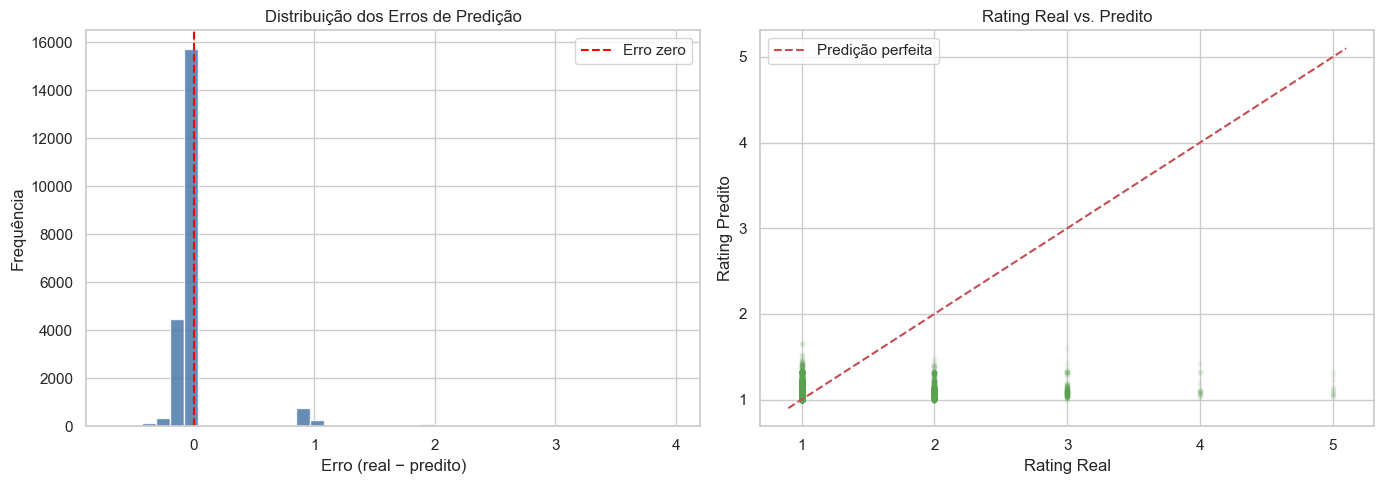

Média do erro  : 0.0077
Desvio padrão  : 0.2945


In [10]:
erros = [pred.r_ui - pred.est for pred in predicoes]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(erros, bins=40, color="#4C78A8", edgecolor="white", alpha=0.85)
axes[0].axvline(0, color="red", linestyle="--", linewidth=1.5, label="Erro zero")
axes[0].set_title("Distribuição dos Erros de Predição")
axes[0].set_xlabel("Erro (real − predito)")
axes[0].set_ylabel("Frequência")
axes[0].legend()

reais    = [pred.r_ui for pred in predicoes]
preditos = [pred.est  for pred in predicoes]
axes[1].scatter(reais, preditos, alpha=0.05, s=10, color="#59A14F")
lim = (min(min(reais), min(preditos)) - 0.1, max(max(reais), max(preditos)) + 0.1)
axes[1].plot(lim, lim, "r--", linewidth=1.5, label="Predição perfeita")
axes[1].set_title("Rating Real vs. Predito")
axes[1].set_xlabel("Rating Real")
axes[1].set_ylabel("Rating Predito")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Média do erro  : {np.mean(erros):.4f}")
print(f"Desvio padrão  : {np.std(erros):.4f}")

#### Interpretando os gráficos

**Histograma de erros (esquerda):** distribui os valores de $r_{ui} - \hat{r}_{ui}$ (real menos predito) para todas as interações do conjunto de teste. Um bom modelo mostra:
- **Centrado em zero**: o modelo não tem viés sistemático — não superestima nem subestima consistentemente
- **Simétrico**: erros positivos e negativos são igualmente prováveis
- **Estreito**: a maioria dos erros está próxima de zero (poucos erros grandes)

**Gráfico real vs predito (direita):** cada ponto é uma interação do conjunto de teste. A linha vermelha tracejada representa a "predição perfeita" (predito = real). Observe:
- **Regressão à média**: as predições tipicamente ficam num intervalo mais estreito do que os rankings reais (ex.: reais vão de 1 a 5, predições ficam entre 2 e 4). Isso é esperado e normal em modelos de filtragem colaborativa — o modelo "prefere" ser conservador quando há incerteza
- **Pontos acima da diagonal**: o modelo subestimou (previu menos engajamento do que o real)
- **Pontos abaixo da diagonal**: o modelo superestimou (previu mais engajamento do que o real)
- **Densidade nos extremos**: os rankings 1 e 5 são mais difíceis de prever com precisão porque são os casos mais extremos do dataset

In [11]:
def recomendar_top_n(modelo, df, user_id, n=10):
    itens_consumidos = set(df[df["user_id"] == user_id]["item_id"])
    itens_nao_vistos = [item for item in df["item_id"].unique() if item not in itens_consumidos]
    predicoes_usuario = [(item, modelo.predict(user_id, item).est) for item in itens_nao_vistos]
    predicoes_usuario.sort(key=lambda x: x[1], reverse=True)
    return pd.DataFrame(predicoes_usuario[:n], columns=["espetáculo", "score_predito"])


usuario_exemplo = (
    df.groupby("user_id")
    .size()
    .reset_index(name="n_interacoes")
    .query("n_interacoes >= 3")
    .sample(1, random_state=42)["user_id"]
    .values[0]
)

historico = df[df["user_id"] == usuario_exemplo][["item_id", "ranking"]]
print(f"=== Usuário {usuario_exemplo} — Histórico ({len(historico)} itens) ===")
print(historico.to_string(index=False))

print(f"\nTop-10 Recomendações:")
recomendacoes = recomendar_top_n(modelo_svd, df, usuario_exemplo, n=10)
print(recomendacoes.to_string(index=False))

=== Usuário 39332 — Histórico (3 itens) ===
                             item_id  ranking
 AFONSO PADILHA - NINGUÉM SE IMPORTA        1
GIOVANA FAGUNDES EM ORGULHO DO PAPAI        1
          RENATO ALBANI EM NOVO SHOW        1

Top-10 Recomendações:
                                                                   espetáculo  score_predito
                                     VOZES NEGRAS – A FORÇA DO CANTO FEMININO       1.337009
                                           PRÊMIO SIM A IGUALDADE RACIAL 2023       1.324359
                                           ESTHER SAMUEL - ÀS MINHAS CRIANÇAS       1.293352
                                                                       ZAQUIM       1.198965
                           CEIÇA MORENO - MEU LUAR PARTICIPAÇÃO:  CHICO CHICO       1.191397
                                  SOMAMOS FESTIVAL - TUIM + PIETÁ + TROPICALS       1.190489
                                                              EVOÉ, O MUSICAL       1.173302
"MÚSI

#### Interpretando as recomendações

A função `recomendar_top_n` implementa o pipeline padrão de recomendação personalizada:
1. **Filtra** todos os espetáculos que o usuário **já viu** (para não recomendar o óbvio)
2. **Prediz** o score de engajamento para cada espetáculo não visto, usando a fórmula $\hat{r}_{ui} = \mu + b_u + b_i + p_u \cdot q_i^T$
3. **Ordena** em ordem decrescente de score predito
4. **Retorna** os top-N com maior score

O **`score_predito`** não é uma nota consciente que o usuário daria — é a estimativa do modelo de quanto aquele usuário se engajaria com aquele espetáculo (em dias distintos de interação), com base nos padrões de comportamento de usuários similares.

**Limitações importantes das recomendações:**
- **Viés de popularidade**: espetáculos com alto $b_i$ (muito visitados) tendem a aparecer nas recomendações mesmo para usuários com perfil diferente
- **Cold-start de item**: espetáculos novos, sem histórico de interações, nunca aparecem nas recomendações — o modelo não tem $q_i$ para eles
- **Interpretação de ausência**: "nunca viu" ≠ "não quer ver" — o modelo não distingue espetáculos desconhecidos de espetáculos deliberadamente evitados

In [12]:
qi = modelo_svd.qi  # (n_items, n_factors)
indice_para_item = {v: full_trainset.to_raw_iid(v) for v in full_trainset.all_items()}

print("=== Espetáculos com maior projeção por fator latente ===\n")
for fator in range(3):
    scores = [(indice_para_item[i], qi[i, fator]) for i in full_trainset.all_items()]
    scores.sort(key=lambda x: x[1], reverse=True)
    print(f"Fator {fator + 1} — Top 5:")
    for nome, score in scores[:5]:
        print(f"  {nome[:65]:<65} ({score:.3f})")
    print()

=== Espetáculos com maior projeção por fator latente ===

Fator 1 — Top 5:
  CEIÇA MORENO - MEU LUAR PARTICIPAÇÃO:  CHICO CHICO                (0.192)
  O ENCONTRO - MALCOLM X E MARTIN LUTHER KING JR                    (0.178)
  MOACYR LUZ E SAMBA DO TRABALHADOR 16 ANOS                         (0.151)
  DAVI MORAES E PEDRO BABY                                          (0.150)
  RAY CONNIFF: THE TRIBUTE SHOW                                     (0.142)

Fator 2 — Top 5:
  SOMAMOS FESTIVAL - THEO BIAL E QUEL                               (0.285)
  VII FESTIVAL INTERNO DO BALLET MANGUINHOS                         (0.207)
  CAFÉ DA MANHÃ MUSICAL - CLÁSSICO & INSTRUMENTAL                   (0.204)
  SOMAMOS FESTIVAL – CHICO BROWN                                    (0.152)
  SESSÃO DA TARDE MUSICAL -  HOMENAGEM À DICK FARNEY COM ZÉ MAZZIOT (0.146)

Fator 3 — Top 5:
  ALEX ALBINO NO SOMAMOS FESTIVAL                                   (0.193)
  BAILE DO LOROZA                                    

#### O que os fatores latentes revelam?

Cada fator $k$ aprendido pelo modelo é um **tema implícito** nos dados. O modelo nunca recebe rótulos como "gênero musical" ou "faixa de preço" — ele infere automaticamente quais características agrupam espetáculos com padrões de consumo similares.

Os espetáculos com **maior projeção positiva** num fator compartilham alguma característica latente que o modelo aprendeu a associar. Pode ser:
- Um **gênero** (ex.: shows de stand-up comedy)
- Um **perfil de preço** (ingressos acessíveis vs premium)
- Um **público-alvo** (familiar, jovem adulto, etc.)
- Uma **época ou temática** (retrospectivas, lançamentos, etc.)

**Como analisar:** olhe para os top-5 espetáculos de cada fator e tente identificar um padrão comum nos títulos. Esse padrão informal é o que aquele fator latente está "representando" no espaço de preferências.

> **Importante:** os fatores latentes **não têm interpretação garantida**. Em muitos casos o padrão não é óbvio, ou um fator captura uma mistura de características. Isso é normal e reflete a complexidade dos comportamentos de consumo cultural. O objetivo principal dos fatores não é ser interpretável, mas sim **predizer** com precisão — a análise de fatores é complementar e exploratória.

## 5. Conclusões

### 5.1. Hiperparâmetros Selecionados e Justificativa

O modelo final foi treinado com os hiperparâmetros encontrados via `GridSearchCV` com 3-fold cross-validation, minimizando RMSE:

- **`n_factors`**: dimensão do espaço latente. Um valor entre 20 e 100 é adequado para a escala desta base (571 espetáculos, ~68 mil usuários). Valores maiores capturam mais nuances, mas elevam o risco de overfitting dada a alta esparsidade (99,71%).
- **`lr_all`**: taxa de aprendizado ideal neste dataset está na faixa de 0,002 a 0,010. Taxas muito altas causam oscilação na convergência; muito baixas, convergência lenta.
- **`reg_all`**: regularização L2 essencial para dados esparsos. Valores entre 0,02 e 0,10 equilibram viés e variância.
- **`n_epochs = 50`**: garante convergência completa após identificar os hiperparâmetros ótimos na busca em grade (que usa 20 épocas).

### 5.2. Pontos Fortes do Modelo

- **Escalabilidade**: Funk SVD escala bem com o volume de interações, sendo mais eficiente que KNN em bases grandes e esparsas.
- **Generalização**: os fatores latentes capturam padrões globais de preferência, indo além de vizinhanças locais.
- **Tratamento de esparsidade**: representações compactas permitem predizer ratings para pares usuário-item não observados.
- **Incorporação de bias**: os termos $b_u$ e $b_i$ capturam tendências sistemáticas (usuários com comportamento consistente; espetáculos popularmente avaliados).

### 5.3. Limitações

- **Cold-start**: usuários ou espetáculos sem histórico de interações não podem ser atendidos pelo modelo sem estratégia complementar.
- **Feedback implícito**: o `ranking` representa dias distintos de interação (1–5), não uma avaliação subjetiva explícita. Pode introduzir ruído, pois dias repetidos podem refletir disponibilidade do usuário, e não necessariamente preferência.
- **Estático no tempo**: o modelo não captura evolução das preferências; mudanças de gosto do usuário ao longo do tempo não são detectadas.

### 5.4. Próximos Passos

- **Comparação com KNN** no notebook `04_avaliacao_inferencia.ipynb`, usando RMSE, MAE, Precision@K, Recall@K e F1@K para selecionar o modelo final.
- **Modelos híbridos**: incorporar `valor_medio_ingresso` e `tipo_evento` como features auxiliares (SVD++ ou abordagem baseada em conteúdo).
- **Estratégia de cold-start**: recomendar por popularidade para novos usuários, com migração gradual para o modelo personalizado após acúmulo de interações.